# Campaña oceanográfica virtual en la Bahía de La Paz
## Descarga de temperatura y salinidad de Copernicus Marine y diagrama T–S

**Objetivo de la clase:** simular una campaña de muestreo de **un día** en la Bahía de La Paz (B.C.S., México).
En lugar de bajar un CTD desde un barco, vamos a usar el reanálisis oceánico global
**GLORYS12** del servicio europeo **Copernicus Marine** (producto `GLOBAL_MULTIYEAR_PHY_001_030`).

Con un modelo podemos hacer algo imposible en un barco: **muestrear toda la bahía al mismo tiempo**.
Usaremos todos los puntos del modelo (todas las celdas y todas las profundidades) de un solo día.

**Pasos:**
1. Instalar las librerías e iniciar sesión en Copernicus Marine.
2. Diseñar la campaña: fecha y región.
3. Descargar temperatura y salinidad de la región.
4. Abrir y explorar el archivo NetCDF.
5. Convertir todos los datos en una tabla.
6. Convertir a TEOS-10 (salinidad absoluta y temperatura conservativa).
7. Calcular las líneas de densidad (isopicnas).
8. Graficar el diagrama T–S.
9. **Tarea:** agregar las masas de agua de Portela et al. (2016).

> **Nota:** si no tienes cuenta de Copernicus, puedes saltarte la descarga. El archivo ya está en la carpeta `datos/` del repositorio.

## 0. Instalación de librerías

Si trabajas en tu computadora, instala las librerías **una sola vez** desde la terminal:

```
pip install copernicusmarine xarray netCDF4 gsw matplotlib cmocean pandas
```

Si trabajas en **Google Colab**, quita el `#` de la siguiente celda y ejecútala.

In [1]:
# Solo para Google Colab: quita el # de la siguiente línea y ejecuta la celda
# !pip install copernicusmarine gsw cmocean

## Librerías

Importamos todas las librerías al inicio del notebook.

In [2]:
# --- Librerías que usaremos en la clase ---
import os                           # revisar si un archivo existe y crear carpetas
import numpy as np                  # cálculos numéricos con arreglos (vectores y matrices)
import pandas as pd                 # tablas de datos (como una hoja de Excel)
import xarray as xr                 # leer archivos NetCDF (.nc), el formato estándar en oceanografía
import matplotlib.pyplot as plt     # hacer gráficas
import cmocean                      # paletas de colores pensadas para oceanografía
import gsw                          # TEOS-10: ecuación de estado del agua de mar
import copernicusmarine             # herramienta oficial para descargar datos de Copernicus Marine

In [3]:
# --- Estilo de las gráficas ---
plt.rcParams.update({
    "font.family": "serif",                          # letra con serifa (tipo libro)
    "font.serif": ["Times New Roman", "DejaVu Serif"],  # si no hay Times, usa DejaVu
    "font.size": 14,                                 # tamaño general de letra
    "axes.labelsize": 16,                            # tamaño de las etiquetas de los ejes
    "axes.titlesize": 16,                            # tamaño de los títulos
    "legend.fontsize": 12,                           # tamaño de la leyenda
    "mathtext.fontset": "stix",                      # letra de las fórmulas ($...$)
})

# --- Carpetas donde guardaremos los datos y las figuras ---
os.makedirs("datos", exist_ok=True)     # exist_ok=True: no marca error si ya existe
os.makedirs("figuras", exist_ok=True)

## 1. Iniciar sesión en Copernicus Marine

1. Crea una cuenta gratuita en <https://data.marine.copernicus.eu/register>.
2. Quita el `#` de la siguiente celda y ejecútala. Te pedirá tu **usuario** y **contraseña**.
3. Tus credenciales se guardan en tu computadora, así que **solo se hace una vez**.
   Después vuelve a poner el `#` para no repetirlo.

In [4]:
# Iniciar sesión (solo la primera vez)
# copernicusmarine.login()

## 2. Diseño de la campaña

Como en una campaña real, primero decidimos **cuándo** y **dónde** vamos a muestrear.

- **Fecha:** 15 de agosto de 2024 (verano).
- **Región:** una caja que cubre la Bahía de La Paz, la **Cuenca Alfonso** (la parte más profunda de la bahía),
  **Boca Grande** y las aguas del **Golfo de California** frente a la bahía.

GLORYS12 tiene una resolución horizontal de 1/12° (unos 9 km). La bahía mide unos 40 × 80 km,
así que el modelo la representa con pocas celdas.

In [5]:
# --- Fecha de la campaña (formato año-mes-día) ---
fecha = "2024-08-15"

# --- Caja (región) que vamos a descargar ---
lon_min, lon_max = -110.9, -109.8   # longitudes (°)
lat_min, lat_max = 24.1, 25.0       # latitudes (°)
prof_min, prof_max = 0, 1500        # profundidades (m)

## 3. Descarga de los datos

Usamos la función `copernicusmarine.subset()`, que descarga **solo un recorte** (subconjunto) del producto:

| Parámetro | Significado |
|---|---|
| `dataset_id` | Nombre del conjunto de datos. `cmems_mod_glo_phy_my_0.083deg_P1D-m` = GLORYS12, promedios **diarios** |
| `variables` | `thetao` = temperatura potencial (°C), `so` = salinidad práctica |
| `minimum_longitude` ... `maximum_latitude` | Límites de la caja |
| `start_datetime`, `end_datetime` | Fechas inicial y final (aquí es el mismo día) |
| `minimum_depth`, `maximum_depth` | Rango de profundidades (m) |

El `dataset_id` y los nombres de las variables aparecen en la página del producto, en la pestaña **Data access**.

Si el archivo ya existe en `datos/`, no se vuelve a descargar.

In [6]:
# Nombre del archivo donde se guardarán los datos
nombre_archivo = "glorys12_bahia_la_paz_" + fecha + ".nc"
archivo = "datos/" + nombre_archivo

# Si el archivo NO existe, lo descargamos
if not os.path.exists(archivo):
    copernicusmarine.subset(
        dataset_id="cmems_mod_glo_phy_my_0.083deg_P1D-m",  # GLORYS12, datos diarios
        variables=["thetao", "so"],                        # temperatura y salinidad
        minimum_longitude=lon_min,
        maximum_longitude=lon_max,
        minimum_latitude=lat_min,
        maximum_latitude=lat_max,
        start_datetime=fecha + "T00:00:00",
        end_datetime=fecha + "T00:00:00",
        minimum_depth=prof_min,
        maximum_depth=prof_max,
        output_directory="datos",                          # carpeta de salida
        output_filename=nombre_archivo,
    )
else:
    print("El archivo ya existe, no se descarga de nuevo:", archivo)

El archivo ya existe, no se descarga de nuevo: datos/glorys12_bahia_la_paz_2024-08-15.nc


## 4. Abrir y explorar los datos

Con `xarray` abrimos el archivo NetCDF. Al imprimirlo vemos:
- **Dimensiones:** `time` (un solo día), `depth`, `latitude`, `longitude`.
- **Coordenadas:** los valores de cada dimensión.
- **Variables:** `thetao` y `so`, con 4 dimensiones cada una.
- **Atributos:** información del producto (unidades, fuente, etc.).

In [7]:
# Abrir el archivo
ds = xr.open_dataset(archivo)

# Ver el contenido (dimensiones, coordenadas, variables y atributos)
ds

<xarray.Dataset> Size: 87kB
Dimensions:    (time: 1, depth: 38, latitude: 11, longitude: 13)
Coordinates:
  * time       (time) datetime64[ns] 8B 2024-08-15
  * depth      (depth) float32 152B 0.494 1.541 2.646 ... 1.245e+03 1.452e+03
  * latitude   (latitude) float32 44B 24.17 24.25 24.33 ... 24.83 24.92 25.0
  * longitude  (longitude) float32 52B -110.8 -110.8 -110.7 ... -109.9 -109.8
Data variables:
    thetao     (time, depth, latitude, longitude) float64 43kB ...
    so         (time, depth, latitude, longitude) float64 43kB ...
Attributes: (12/25)
    Conventions:               CF-1.4
    bulletin_date:             2021-07-07 00:00:00
    bulletin_type:             operational
    comment:                   CMEMS product
    domain_name:               GL12
    easting:                   longitude
    ...                        ...
    references:                http://www.mercator-ocean.fr
    source:                    MERCATOR GLORYS12V1
    title:                     daily mean fields from Global Ocean Physics An...
    z_max:                     5727.9169921875
    z_min:                     0.49402499198913574
    copernicusmarine_version:  2.5.0

In [8]:
# Revisar las unidades y el nombre largo de cada variable
print("thetao:", ds["thetao"].attrs["long_name"], "-", ds["thetao"].attrs["units"])
print("so:    ", ds["so"].attrs["long_name"], "-", ds["so"].attrs["units"])

# Niveles de profundidad del modelo, redondeados a metros (no están espaciados igual)
print("\nProfundidades del modelo (m):")
print(np.round(ds["depth"].values).astype(int))

thetao: Temperature - degrees_C
so:     Salinity - 1e-3

Profundidades del modelo (m):
[   0    2    3    4    5    6    8   10   11   13   16   18   22   25
   29   34   40   47   56   66   78   92  110  131  156  186  222  266
  318  380  454  541  644  763  902 1062 1245 1452]


## 5. Todos los datos en una tabla

Los datos de `xarray` tienen 4 dimensiones (tiempo, profundidad, latitud, longitud).
Para el diagrama T–S nos conviene una **tabla** con una fila por cada punto del modelo:

- `isel(time=0)` toma el único día descargado.
- `to_dataframe()` convierte los datos en una tabla de `pandas`.
- `reset_index()` convierte las coordenadas (profundidad, latitud, longitud) en columnas normales.
- `dropna()` quita los puntos sin dato (`NaN`): la tierra y lo que está por debajo del fondo marino.

In [9]:
# Convertir los datos del día en una tabla: una fila por punto (profundidad, latitud, longitud)
tabla = ds.isel(time=0).to_dataframe().reset_index()

# Quitar los puntos sin dato (tierra y debajo del fondo)
tabla = tabla.dropna()

# Cambiar los nombres de las columnas a español
tabla = tabla.rename(columns={"time": "fecha", "depth": "prof", "latitude": "lat",
                              "longitude": "lon", "thetao": "temp", "so": "sal"})

# ¿Cuántos puntos tenemos?
print("Total de puntos con dato:", len(tabla))

# Ver las primeras filas
tabla.head(10)

Total de puntos con dato: 3047


,prof,lat,lon,temp,sal,fecha
10,0.494025,24.166666,-110.000000,29.910184,35.511338,2024-08-15
11,0.494025,24.166666,-109.916664,30.045686,35.511338,2024-08-15
17,0.494025,24.250000,-110.500000,29.710227,35.578478,2024-08-15
18,0.494025,24.250000,-110.416664,29.664083,35.580004,2024-08-15
19,0.494025,24.250000,-110.333336,29.601825,35.563219,2024-08-15
22,0.494025,24.250000,-110.083336,29.683126,35.554064,2024-08-15
23,0.494025,24.250000,-110.000000,29.655293,35.547960,2024-08-15
24,0.494025,24.250000,-109.916664,29.851588,35.529649,2024-08-15
25,0.494025,24.250000,-109.833336,29.875027,35.525071,2024-08-15
29,0.494025,24.333334,-110.583336,29.826685,35.563219,2024-08-15


In [10]:
# Guardar la tabla en un archivo de texto (CSV) que se abre en Excel
tabla.to_csv("datos/tabla_bahia_la_paz_" + fecha + ".csv", index=False)

## 6. Conversión a TEOS-10

Desde 2010 el estándar internacional para el agua de mar es **TEOS-10**. Sus variables principales son:

- **Salinidad absoluta** $S_A$ (g kg$^{-1}$): masa de sales disueltas por kilogramo de agua de mar.
- **Temperatura conservativa** $\Theta$ (°C): representa mejor el contenido de calor que la temperatura potencial.

Portela et al. (2016) definen las masas de agua con $S_A$ y $\Theta$, así que convertimos con la librería `gsw`:

| Función | Qué calcula |
|---|---|
| `gsw.p_from_z(z, lat)` | presión (dbar) a partir de la altura $z$ (negativa bajo el mar) |
| `gsw.SA_from_SP(SP, p, lon, lat)` | salinidad absoluta a partir de la salinidad práctica |
| `gsw.CT_from_pt(SA, pt)` | temperatura conservativa a partir de la temperatura potencial |
| `gsw.sigma0(SA, CT)` | anomalía de densidad potencial referida a la superficie, $\sigma_0 = \rho - 1000$ (kg m$^{-3}$) |

Las funciones de `gsw` trabajan con columnas completas, así que no necesitamos un ciclo `for`.

In [11]:
# Presión (dbar). z es negativa hacia abajo, por eso usamos -prof
tabla["pres"] = gsw.p_from_z(-tabla["prof"], tabla["lat"])

# Salinidad absoluta (g/kg)
tabla["SA"] = gsw.SA_from_SP(tabla["sal"], tabla["pres"], tabla["lon"], tabla["lat"])

# Temperatura conservativa (°C)
tabla["CT"] = gsw.CT_from_pt(tabla["SA"], tabla["temp"])

# Anomalía de densidad potencial (kg/m³)
tabla["sigma0"] = gsw.sigma0(tabla["SA"], tabla["CT"])

# Resumen estadístico de las nuevas columnas
tabla[["SA", "CT", "sigma0"]].describe().round(2)

,SA,CT,sigma0
count,3047.00,3047.00,3047.00
mean,35.28,21.72,24.11
std,0.33,7.96,1.83
min,34.47,2.98,21.51
25%,34.98,14.18,22.32
50%,35.34,24.41,23.66
75%,35.58,29.34,25.99
max,35.76,30.76,27.57


## 7. Líneas de densidad (isopicnas)

En un diagrama T–S, las líneas de igual densidad se dibujan "de fondo". Para obtenerlas:

1. Creamos una **malla** de valores de $S_A$ y $\Theta$ que cubra todo el diagrama (`np.meshgrid`).
2. Calculamos $\sigma_0$ en cada punto de la malla.
3. Dibujamos los contornos con `plt.contour`.

In [12]:
# Valores de los ejes del diagrama (límites un poco más amplios que los datos)
SA_eje = np.linspace(34.2, 36.0, 200)   # 200 valores de salinidad absoluta
CT_eje = np.linspace(2, 32, 200)        # 200 valores de temperatura conservativa

# Malla 2D: cada combinación de SA y CT
SA_malla, CT_malla = np.meshgrid(SA_eje, CT_eje)

# Densidad potencial en cada punto de la malla
sigma0_malla = gsw.sigma0(SA_malla, CT_malla)

print("sigma0 va de", round(sigma0_malla.min(), 1), "a", round(sigma0_malla.max(), 1), "kg/m³")

sigma0 va de 20.3 a 28.6 kg/m³


## 8. Diagrama T–S

Cada punto es un punto del modelo (una celda a una profundidad). El color indica la profundidad.
Las líneas grises discontinuas son las isopicnas $\sigma_0$ (kg m$^{-3}$).

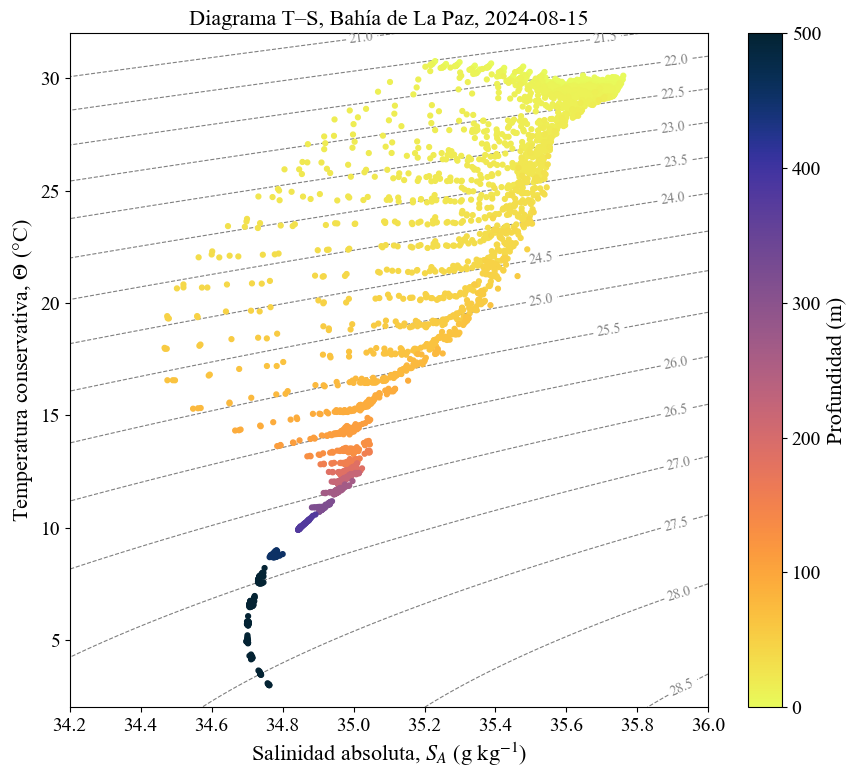

In [34]:
fig, ax = plt.subplots(figsize=(9, 8))

# 1) Isopicnas de fondo
isopicnas = ax.contour(SA_malla, CT_malla, sigma0_malla,
                       levels=np.arange(21, 29, 0.5),   # de 21 a 28.5 cada 0.5
                       colors="gray", linestyles="--", linewidths=0.8)
ax.clabel(isopicnas, fmt="%.1f", fontsize=10)           # etiquetas sobre las líneas

# 2) Datos de la campaña, coloreados por profundidad
puntos = ax.scatter(tabla["SA"], tabla["CT"], c=tabla["prof"], cmap=cmocean.cm.thermal_r,
                    s=12, zorder=3, vmin=0, vmax=500)
plt.colorbar(puntos, ax=ax, label="Profundidad (m)")

# 3) Etiquetas y formato
ax.set_xlabel(r"Salinidad absoluta, $S_A$ (g kg$^{-1}$)")
ax.set_ylabel(r"Temperatura conservativa, $\Theta$ (°C)")
ax.set_title("Diagrama T–S, Bahía de La Paz, " + fecha)
ax.set_xlim(34.2, 36.0)
ax.set_ylim(2, 32)

plt.tight_layout()
plt.savefig("figuras/diagrama_TS.png", dpi=200)
plt.show()

## 9. Tarea: masas de agua de Portela et al. (2016)

Portela, E., et al. (2016). *Water masses and circulation in the tropical Pacific off central Mexico and surrounding areas.*
Journal of Physical Oceanography, 46(10), 3069–3081. <https://doi.org/10.1175/JPO-D-16-0068.1>

**Instrucciones:**

1. Lee el artículo y localiza la **Tabla 1**. Usa los límites en **TEOS-10** (temperatura conservativa y salinidad absoluta).
2. Copia el diagrama T–S de la sección 8 en la celda de abajo y dibuja un **rectángulo** para cada masa de agua.
3. Escribe la **abreviatura** de cada masa de agua dentro de su rectángulo (por ejemplo, GCW).
4. Algunos límites son abiertos (por ejemplo "> 12 °C"). En esos casos usa el borde del diagrama como límite.
5. Responde:
   - ¿Qué masas de agua encontraste? ¿A qué profundidades?
   - ¿Hay puntos que no caen en ninguna masa de agua? ¿Qué significan?
   - ¿Cambiaría el resultado en invierno? Cambia la `fecha` (por ejemplo `"2024-02-15"`),
     vuelve a correr el notebook y compara.

**Pista:** un rectángulo se dibuja uniendo sus cuatro esquinas y regresando a la primera.
En este ejemplo los números son **inventados**:

```python
# Rectángulo de ejemplo: SA entre 35.0 y 35.5, CT entre 10 y 15
ax.plot([35.0, 35.5, 35.5, 35.0, 35.0],   # valores de SA de las esquinas
        [10, 10, 15, 15, 10],             # valores de CT de las esquinas
        color="red", linewidth=2)
ax.text(35.05, 14, "EJEMPLO", color="red", fontsize=12)   # nombre de la masa de agua
```

In [14]:
# Escribe aquí tu código para la tarea
